# Figure 6 — Python ISR table preparation and saved results

This notebook presents the Python workflow that prepares patient-level ISR and survival tables, followed by the current publication Figure 6. Code is displayed in unexecuted cells; images are embedded from saved publication results.

The analysis unit is the patient. H&E-derived ISR is the PIR-to-PSM tile-count ratio; the IMC score uses `clip((N_PIR + 1) / (N_PSM + 1), 0.1, 10)`.

[Source script](03_prepare_public_isr_tables.py) · [Workflow and input schemas](README.md) · [R analysis report](Figure6.md) · [All Figure reports](../../docs/rmd_display.md)

## Python workflow

### Configuration and source-table fields

The inputs are Supplementary Tables 1 and 5, saved IMC scores, and discovery-cohort H&E scores.

In [ ]:
#!/usr/bin/env python3
"""Prepare de-identified patient-level ISR tables for public distribution.

Target/purpose: expose the FDZS-1 and FDZS-2 patient-level inputs used by the
public ISR and survival workflows. Inputs: the current Supplementary Tables
workbook, saved IMC patient scores, and discovery H&E ISR table selected in
``CONFIG``. Outputs: four TSV files in ``output_dir``. Ordered workflow: read
the current patient tables, reconcile saved ISR values, assign release IDs,
derive the discovery cutoff, validate the current ISR groups, and write TSVs.
"""

from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd


# Edit these paths before running this interactive Figure 6 entry point.
CONFIG = {
    "supplementary_workbook": Path("/path/to/Supplementary Tables.xlsx"),
    "imc_scores": Path("/path/to/iBDME_patient_scores.csv"),
    "discovery_he_scores": Path("/path/to/discovery_pred.csv"),
    "output_dir": Path("/path/to/derived_results/ISR"),
}

S1_COLUMNS = {
    "Patient ID",
    "Recurrence status during follow-up",
    "RFS time from completion of primary and liver metastasis resection (months)",
    "Postoperative adjuvant treatment group",
}
S5_COLUMNS = {
    "Patient ID",
    "RFS event status (1 = recurrence; 0 = censored)",
    "RFS time from completion of primary and liver metastasis resection (months)",
    "Treatment",
    "ISR",
    "ISR group",
    "Age",
    "Gender",
    "Fong score",
    "KRAS mutation",
    "TBS",
    "CRLM number",
    "CRLM_size",
}




### Read clinical tables and saved ISR values

Clinical records and score tables are joined through patient and WSI identifiers.

In [ ]:
def _require_columns(frame: pd.DataFrame, columns: set[str], source: str) -> None:
    """Fail when a public-table source lacks a required field.

    Parameters: ``frame`` is the loaded table, ``columns`` is the required set,
    and ``source`` identifies the input in an error message.
    Returns: no value; raises ``ValueError`` for missing columns.
    """
    # Validate only fields consumed by the public patient-level exports.
    missing = columns - set(frame.columns)
    if missing:
        raise ValueError(f"{source} is missing columns: {sorted(missing)}")


def read_sources(config: dict[str, Path]) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Read and validate the two patient tables and saved ISR sources.

    Parameters: ``config`` supplies workbook, IMC-score, and H&E-score paths.
    Returns: Supplementary Tables 1 and 5, IMC scores, and discovery H&E scores.
    """
    # The second workbook row contains the displayed column headers.
    table1 = pd.read_excel(
        config["supplementary_workbook"], sheet_name="Supplementary Table 1", header=1
    )
    table5 = pd.read_excel(
        config["supplementary_workbook"], sheet_name="Supplementary Table 5", header=1
    )
    imc = pd.read_csv(config["imc_scores"])
    he = pd.read_csv(config["discovery_he_scores"])
    _require_columns(table1, S1_COLUMNS, "Supplementary Table 1")
    _require_columns(table5, S5_COLUMNS, "Supplementary Table 5")
    _require_columns(
        imc, {"PID", "n_bdme_i", "n_bdme_s", "easy_bdme_score"}, "IMC scores"
    )
    _require_columns(
        he,
        {"wsi_id", "bile_1_count", "bile_2_count", "ratio_bile1_to_bile2"},
        "discovery H&E scores",
    )
    if len(table1) != 35 or len(table5) != 95:
        raise ValueError("Expected 35 FDZS-1 rows and 95 FDZS-2 rows")
    if not table1["Patient ID"].is_unique or not table5["Patient ID"].is_unique:
        raise ValueError("Patient-table rows must be uniquely addressable")
    if not imc["PID"].is_unique or not he["wsi_id"].is_unique:
        raise ValueError("Saved FDZS-1 ISR identifiers must be unique")
    return table1, table5, imc, he




### Prepare the discovery cohort

The FDZS-1 export retains 35 patient rows and identifies the 34 patients with H&E-derived ISR used in Figure 6.

In [ ]:
def build_fdzs1_table(
    table1: pd.DataFrame, imc: pd.DataFrame, he: pd.DataFrame
) -> pd.DataFrame:
    """Build the 35-patient FDZS-1 ISR and survival table.

    Parameters: ``table1`` contains clinical records; ``imc`` and ``he`` contain
    saved patient-level ISR components.
    Returns: a 35-row table with public B/W identifiers and both ISR measures.
    """
    # Verify the two operational score definitions before joining patient records.
    expected_imc = np.clip((imc["n_bdme_i"] + 1) / (imc["n_bdme_s"] + 1), 0.1, 10)
    if not np.allclose(imc["easy_bdme_score"], expected_imc, rtol=0, atol=1e-8):
        raise ValueError("Saved IMC ISR does not match the operational definition")
    if (he["bile_2_count"] == 0).any():
        raise ValueError("Discovery H&E PSM tile counts must be nonzero")
    expected_he = he["bile_1_count"] / he["bile_2_count"]
    if not np.allclose(he["ratio_bile1_to_bile2"], expected_he, rtol=0, atol=1e-8):
        raise ValueError("Saved H&E ISR does not match the PIR/PSM tile ratio")

    treatment_map = {
        "FOLFOX alone": "Chemo",
        "FOLFOX plus targeted therapy": "Combo",
    }
    event_map = {"Recurrence": 1, "No recurrence": 0}
    base = table1[
        [
            "Patient ID",
            "Recurrence status during follow-up",
            "RFS time from completion of primary and liver metastasis resection (months)",
            "Postoperative adjuvant treatment group",
        ]
    ].rename(
        columns={
            "Patient ID": "patient_id",
            "RFS time from completion of primary and liver metastasis resection (months)": "rfs_time_months",
        }
    )
    base["rfs_event"] = base["Recurrence status during follow-up"].map(event_map)
    base["treatment"] = base["Postoperative adjuvant treatment group"].map(treatment_map)
    if base[["rfs_event", "treatment"]].isna().any().any():
        raise ValueError("FDZS-1 recurrence or treatment labels do not match the public contract")

    # Left joins retain all 35 IMC-cohort patients and show score availability.
    result = base.merge(
        imc[["PID", "n_bdme_i", "n_bdme_s", "easy_bdme_score"]],
        left_on="patient_id",
        right_on="PID",
        how="left",
        validate="one_to_one",
    ).merge(
        he[["wsi_id", "bile_1_count", "bile_2_count", "ratio_bile1_to_bile2"]],
        left_on="patient_id",
        right_on="wsi_id",
        how="left",
        validate="one_to_one",
    )
    result["cohort"] = "FDZS-1"
    result["analysis_role"] = "discovery"
    result["figure6_included"] = result["ratio_bile1_to_bile2"].notna().astype(int)
    result = result.rename(
        columns={
            "n_bdme_i": "imc_pir_count",
            "n_bdme_s": "imc_psm_count",
            "easy_bdme_score": "imc_derived_isr",
            "bile_1_count": "he_pir_tile_count",
            "bile_2_count": "he_psm_tile_count",
            "ratio_bile1_to_bile2": "isr",
        }
    )
    columns = [
        "patient_id",
        "wsi_id",
        "cohort",
        "analysis_role",
        "figure6_included",
        "imc_pir_count",
        "imc_psm_count",
        "imc_derived_isr",
        "he_pir_tile_count",
        "he_psm_tile_count",
        "isr",
        "rfs_time_months",
        "rfs_event",
        "treatment",
    ]
    if int(result["figure6_included"].sum()) != 34:
        raise ValueError("Expected 34 FDZS-1 patients with H&E-derived ISR")
    return result[columns].sort_values("patient_id").reset_index(drop=True)




### Prepare the independent test cohort

The FDZS-2 export contains 95 patients, release identifiers, treatment, recurrence follow-up, ISR, and clinical variables. ISR groups use the discovery-cohort median.

In [ ]:
def build_fdzs2_table(table5: pd.DataFrame, cutoff: float) -> pd.DataFrame:
    """Build the 95-patient pseudonymized FDZS-2 Figure 6 table.

    Parameters: ``table5`` is the current Supplementary Table 5 and ``cutoff``
    is the discovery-cohort median H&E-derived ISR.
    Returns: a de-identified table matching the public Figure 6 input schema.
    """
    # Stable release IDs preserve the patient and WSI row mapping.
    source_wsi = table5["Patient ID"].astype(str)
    wsi_order = pd.Index(source_wsi.drop_duplicates())
    wsi_map = {value: f"FDZS2-WSI{index:03d}" for index, value in enumerate(wsi_order, 1)}
    result = pd.DataFrame(
        {
            "patient_id": [f"FDZS2-P{index:03d}" for index in range(1, len(table5) + 1)],
            "wsi_id": source_wsi.map(wsi_map),
            "cohort": "FDZS-2",
            "analysis_role": "independent_test",
            "isr": pd.to_numeric(table5["ISR"]),
            "isr_group": table5["ISR group"].astype(str),
            "rfs_time_months": pd.to_numeric(
                table5["RFS time from completion of primary and liver metastasis resection (months)"]
            ),
            "rfs_event": pd.to_numeric(
                table5["RFS event status (1 = recurrence; 0 = censored)"], downcast="integer"
            ),
            "treatment": table5["Treatment"].astype(str),
            "TBS": pd.to_numeric(table5["TBS"]),
            "CRLM_number": pd.to_numeric(table5["CRLM number"]),
            "CRLM_size": pd.to_numeric(table5["CRLM_size"]),
            "fong_score": pd.to_numeric(table5["Fong score"]),
            "KRAS_mutation": pd.to_numeric(table5["KRAS mutation"]),
            "age_years": pd.to_numeric(table5["Age"]),
            "gender_code": pd.to_numeric(table5["Gender"]),
        }
    )
    expected_group = np.where(result["isr"] > cutoff, "High", "Low")
    if not np.array_equal(expected_group, result["isr_group"].to_numpy()):
        raise ValueError("FDZS-2 ISR groups do not match the discovery median cutoff")
    if result["patient_id"].duplicated().any() or result.isna().any().any():
        raise ValueError("FDZS-2 public rows must be complete with unique patient IDs")
    return result




### Record cohort membership and ISR definitions

The assignment table contains the 34 discovery and 95 independent-test patients. The definition table records IMC and H&E ISR formulas and the grouping cutoff.

In [ ]:
def build_assignment(fdzs1: pd.DataFrame, fdzs2: pd.DataFrame) -> pd.DataFrame:
    """Create the public discovery/test patient assignment table.

    Parameters: ``fdzs1`` and ``fdzs2`` are the prepared public patient tables.
    Returns: 129 patient rows with cohort and analysis-role labels.
    """
    # Figure 6 discovery membership is defined by available H&E-derived ISR.
    discovery = fdzs1.loc[
        fdzs1["figure6_included"].eq(1), ["patient_id", "cohort", "analysis_role"]
    ]
    test = fdzs2[["patient_id", "cohort", "analysis_role"]]
    result = pd.concat([discovery, test], ignore_index=True)
    if len(result) != 129 or result["patient_id"].duplicated().any():
        raise ValueError("Expected 34 discovery and 95 independent-test patient assignments")
    return result


def build_definition_table(cutoff: float) -> pd.DataFrame:
    """Describe the operational ISR definitions and discovery-derived cutoff.

    Parameters: ``cutoff`` is the median H&E-derived ISR in FDZS-1.
    Returns: two rows defining IMC- and H&E-derived ISR.
    """
    # Keep formulas and threshold provenance beside the distributed score values.
    return pd.DataFrame(
        [
            {
                "score_name": "IMC-derived ISR",
                "analysis_unit": "patient",
                "formula": "clip((N_PIR + 1) / (N_PSM + 1), 0.1, 10)",
                "cutoff_rule": "continuous patient-level score",
                "numeric_cutoff": np.nan,
            },
            {
                "score_name": "H&E-derived ISR",
                "analysis_unit": "WSI mapped to patient",
                "formula": "N_PIR_tiles / N_PSM_tiles",
                "cutoff_rule": "High if ISR > FDZS-1 discovery median; Low otherwise",
                "numeric_cutoff": cutoff,
            },
        ]
    )




### Export the four public tables

The workflow writes patient ISR tables, cohort assignments, and score definitions to the configured output directory.

In [ ]:
def run(config: dict[str, Path]) -> None:
    """Write the four public ISR tables from editable configuration.

    Parameters: ``config`` supplies all source paths and ``output_dir``.
    Returns: no value; writes four tab-delimited release artifacts.
    """
    # Build the discovery table first because its median defines both cohorts.
    table1, table5, imc, he = read_sources(config)
    fdzs1 = build_fdzs1_table(table1, imc, he)
    cutoff = float(fdzs1.loc[fdzs1["figure6_included"].eq(1), "isr"].median())
    fdzs2 = build_fdzs2_table(table5, cutoff)
    assignment = build_assignment(fdzs1, fdzs2)
    definitions = build_definition_table(cutoff)

    output_dir = config["output_dir"]
    output_dir.mkdir(parents=True, exist_ok=True)
    fdzs1.to_csv(output_dir / "FDZS1_patient_level_ISR.tsv", sep="\t", index=False)
    fdzs2.to_csv(output_dir / "FDZS2_patient_level_ISR_RFS.tsv", sep="\t", index=False)
    assignment.to_csv(output_dir / "SpMap_patient_cohort_assignment.tsv", sep="\t", index=False)
    definitions.to_csv(output_dir / "ISR_definition_and_cutoff.tsv", sep="\t", index=False)
    for path in sorted(output_dir.glob("*.tsv")):
        print(path)


if __name__ == "__main__":
    run(CONFIG)


## Figure 6

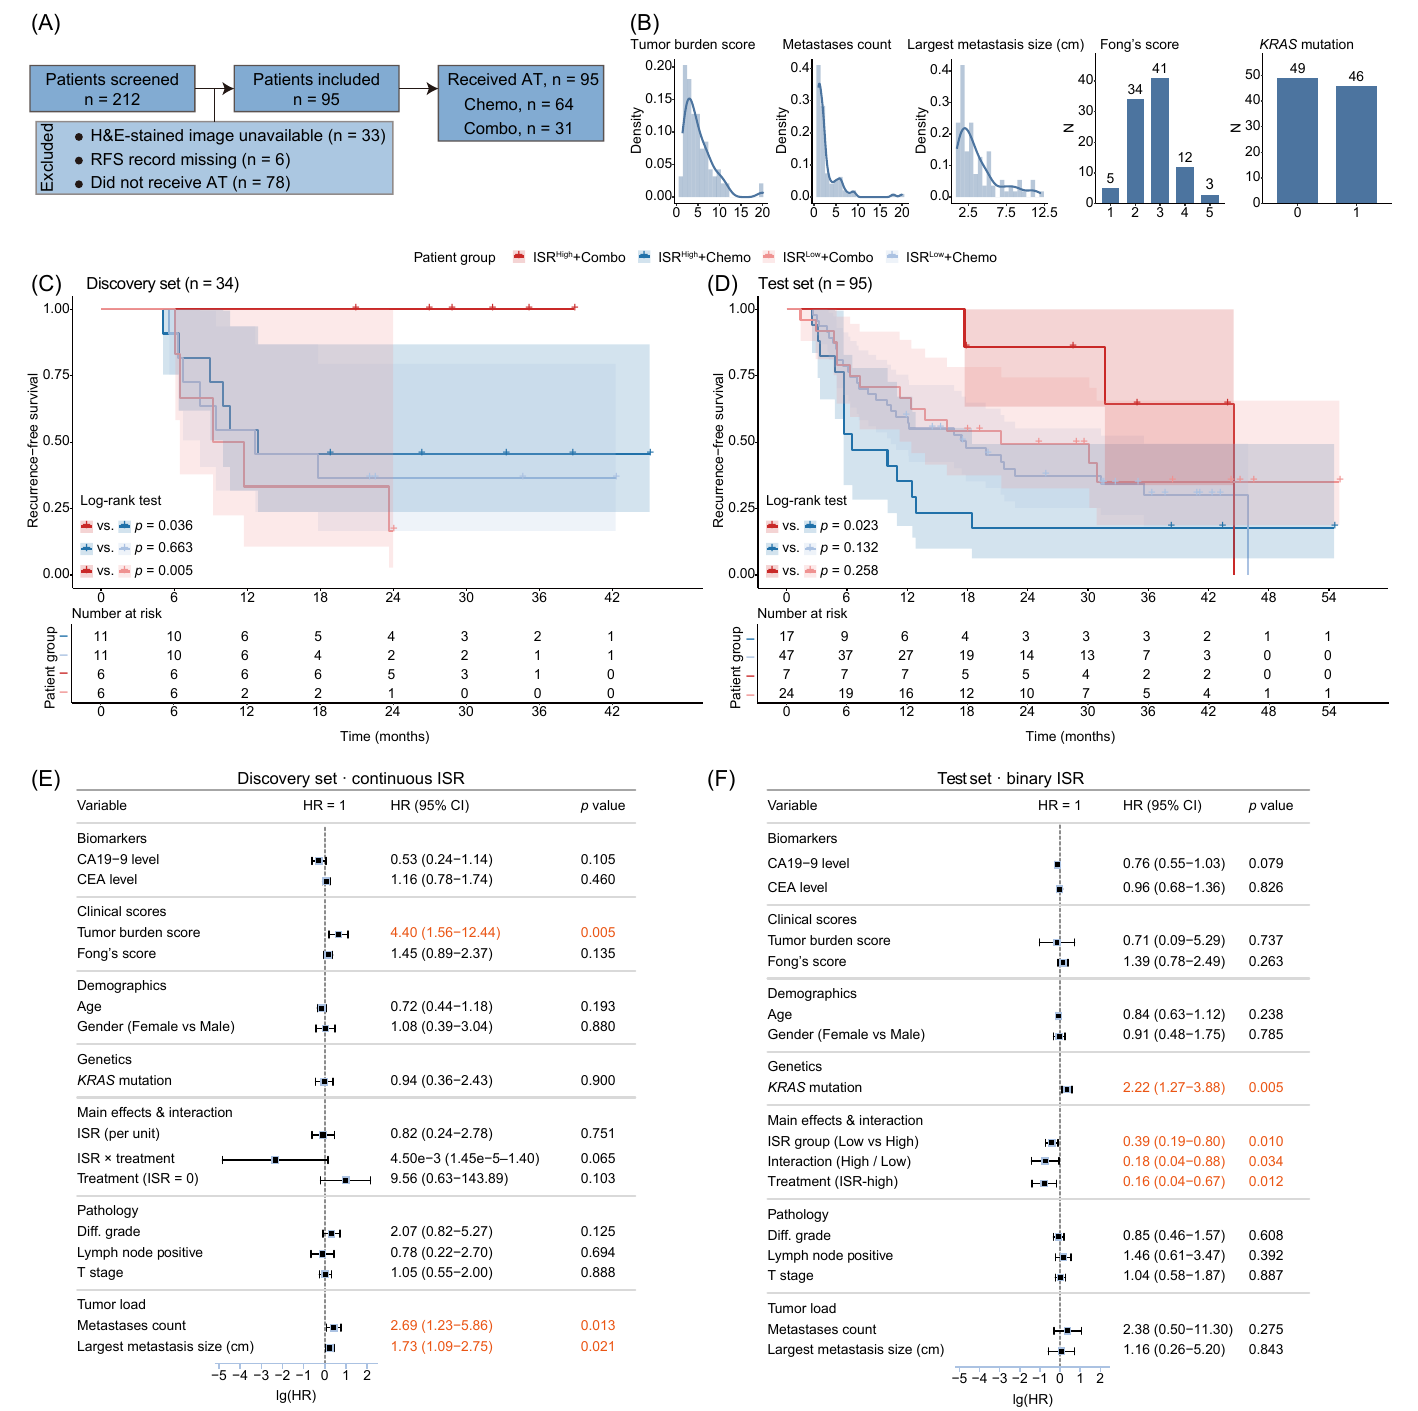

**Figure 6. SpMap-derived ISR stratifies recurrence risk after adjuvant therapy in CRLM.** (A) FDZS-2 patient inclusion and treatment groups. (B) Test-cohort TBS, metastases count, largest metastasis size, Fong score, and KRAS status. (C-D) RFS for 34 discovery and 95 test patients in four ISR-by-treatment groups; red and blue denote Combo and Chemo, with darker shades indicating High ISR. Shading shows 95% confidence intervals, crosses indicate censoring, and risk tables give patients at risk. (E-F) Cox forest plots for the discovery and test cohorts. Forest coordinates are log10(HR), with HR = 1 as reference; numerical columns report HRs, 95% confidence intervals, and nominal P values. [Download the original publication PDF](report_assets/figure6_publication.pdf).

## Related analyses

The [R report](Figure6.md) presents clinical distributions, Kaplan–Meier analyses, and adjusted Cox models, together with Figures S13–S14. [Continuous and binary ISR models](05_continuous_and_binary_isr_cox.R) are provided for both cohorts. The [SpMap workflow](../Figure5/Figure5_python.ipynb) describes the upstream H&E inference and ISR aggregation.